# Customer Churn Prediction System — Deep Learning Project

**Problem:** predict if a telecom customer will leave the service (binary classification).

**Dataset:** Telco Customer Churn (IBM / Kaggle), 7043 customers.

| Required component | Section |
|---|---|
| Data preprocessing | 2, 3, 4, 5 |
| Model design (ANN) | 6 |
| Regularization | 7 |
| Hyperparameter tuning | 8 |
| Evaluation metrics | 9 |
| Model saving and loading | 10 |
| Inference pipeline | 11 |

## 0. Setup

In [1]:
!pip install -q keras-tuner

In [2]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import regularizers
from tensorflow.keras import callbacks
import keras_tuner as kt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import ConfusionMatrixDisplay
import joblib

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Load the Data

In [5]:
DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Data Cleaning

In [7]:
df = df.drop("customerID", axis=1)
print(df.shape)

(7043, 20)


In [8]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Bad TotalCharges rows:", df["TotalCharges"].isna().sum())
print(df.loc[df["TotalCharges"].isna(), "tenure"].unique())

Bad TotalCharges rows: 11
[0]


In [9]:
df = df.dropna()
df = df.reset_index(drop=True)
print(df.shape)

(7032, 20)


In [10]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print(df["Churn"].value_counts())
print(df["Churn"].mean())

Churn
0    5163
1    1869
Name: count, dtype: int64
0.26578498293515357


## 3. Exploratory Analysis

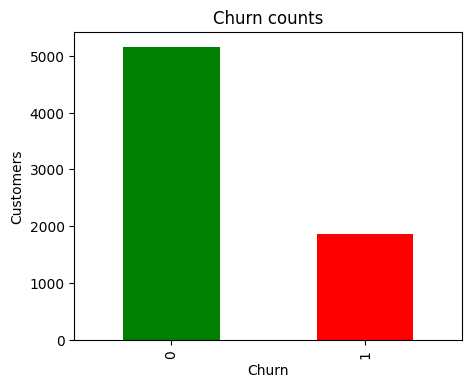

In [11]:
plt.figure(figsize=(5, 4))
df["Churn"].value_counts().plot(kind="bar", color=["green", "red"])
plt.title("Churn counts")
plt.xlabel("Churn")
plt.ylabel("Customers")
plt.show()

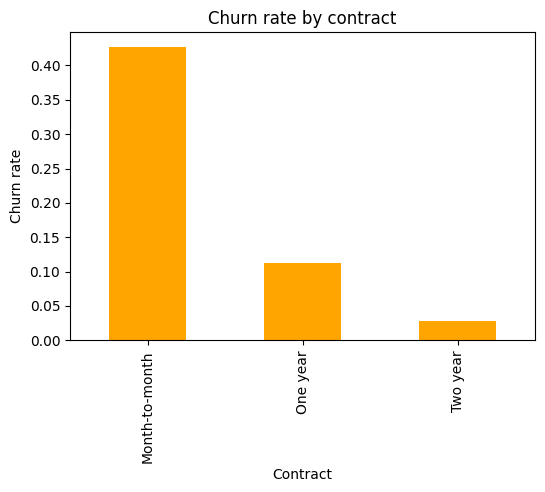

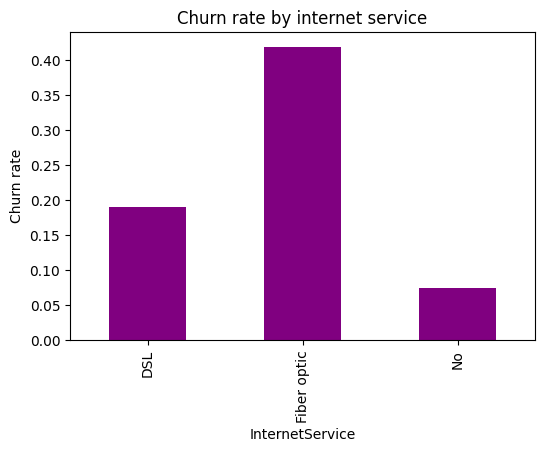

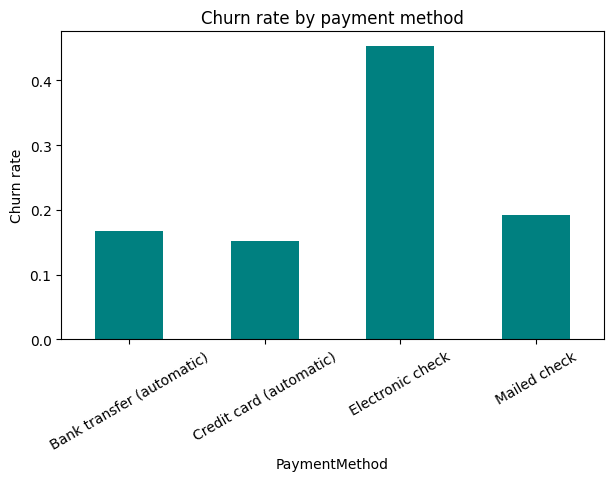

In [12]:
plt.figure(figsize=(6, 4))
df.groupby("Contract")["Churn"].mean().plot(kind="bar", color="orange")
plt.title("Churn rate by contract")
plt.ylabel("Churn rate")
plt.show()

plt.figure(figsize=(6, 4))
df.groupby("InternetService")["Churn"].mean().plot(kind="bar", color="purple")
plt.title("Churn rate by internet service")
plt.ylabel("Churn rate")
plt.show()

plt.figure(figsize=(7, 4))
df.groupby("PaymentMethod")["Churn"].mean().plot(kind="bar", color="teal")
plt.title("Churn rate by payment method")
plt.ylabel("Churn rate")
plt.xticks(rotation=30)
plt.show()

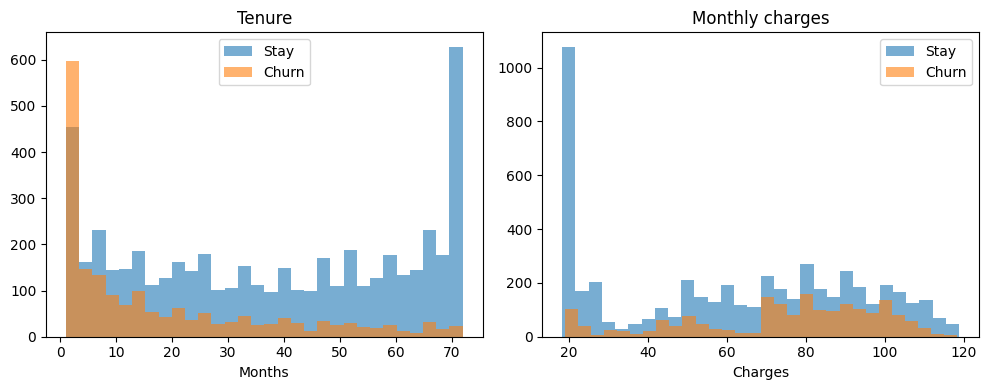

In [13]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df.loc[df["Churn"] == 0, "tenure"], bins=30, alpha=0.6, label="Stay")
plt.hist(df.loc[df["Churn"] == 1, "tenure"], bins=30, alpha=0.6, label="Churn")
plt.title("Tenure")
plt.xlabel("Months")
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(df.loc[df["Churn"] == 0, "MonthlyCharges"], bins=30, alpha=0.6, label="Stay")
plt.hist(df.loc[df["Churn"] == 1, "MonthlyCharges"], bins=30, alpha=0.6, label="Churn")
plt.title("Monthly charges")
plt.xlabel("Charges")
plt.legend()

plt.tight_layout()
plt.show()

## 4. Feature Engineering

In [14]:
df["AvgChargePerMonth"] = df["TotalCharges"] / df["tenure"]

YES_SERVICES = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

df["TotalServices"] = 0
for col in YES_SERVICES:
    df["TotalServices"] = df["TotalServices"] + (df[col] == "Yes").astype(int)
df["TotalServices"] = df["TotalServices"] + (df["InternetService"] != "No").astype(int)

TENURE_BINS = [-1, 12, 24, 48, 72]
TENURE_LABELS = ["0-1y", "1-2y", "2-4y", "4-6y"]
df["TenureGroup"] = pd.cut(df["tenure"], bins=TENURE_BINS, labels=TENURE_LABELS)

df[["tenure", "MonthlyCharges", "TotalCharges", "AvgChargePerMonth", "TotalServices", "TenureGroup"]].head()

,tenure,MonthlyCharges,TotalCharges,AvgChargePerMonth,TotalServices,TenureGroup
0,1,29.85,29.85,29.850000,2,0-1y
1,34,56.95,1889.50,55.573529,4,2-4y
2,2,53.85,108.15,54.075000,4,0-1y
3,45,42.30,1840.75,40.905556,4,2-4y
4,2,70.70,151.65,75.825000,2,0-1y


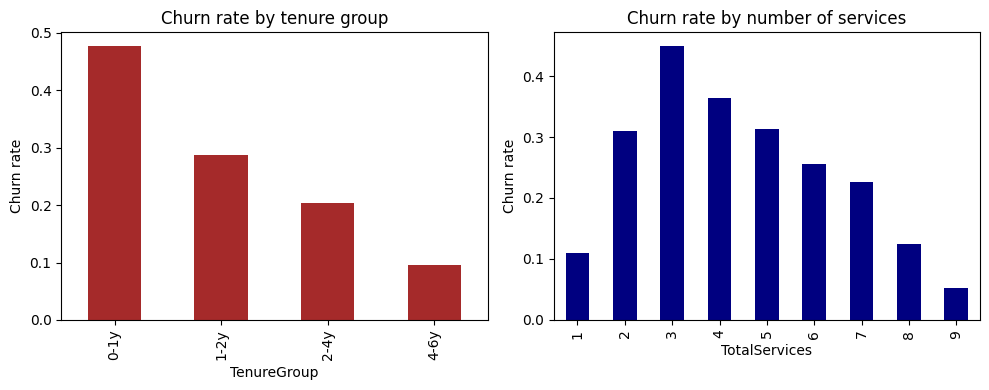

In [15]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
df.groupby("TenureGroup", observed=True)["Churn"].mean().plot(kind="bar", color="brown")
plt.title("Churn rate by tenure group")
plt.ylabel("Churn rate")

plt.subplot(1, 2, 2)
df.groupby("TotalServices")["Churn"].mean().plot(kind="bar", color="navy")
plt.title("Churn rate by number of services")
plt.ylabel("Churn rate")

plt.tight_layout()
plt.show()

## 5. Encoding, Splitting and Scaling

In [16]:
BINARY_COLS = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]
for col in BINARY_COLS:
    df[col] = df[col].map({"No": 0, "Yes": 1})

df["gender"] = df["gender"].map({"Female": 0, "Male": 1})

MULTI_COLS = ["MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
              "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
              "Contract", "PaymentMethod", "TenureGroup"]

df = pd.get_dummies(df, columns=MULTI_COLS, drop_first=True)
print(df.shape)
df.head()

(7032, 36)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureGroup_1-2y,TenureGroup_2-4y,TenureGroup_4-6y
0,0,0,1,0,1,0,1,29.85,29.85,0,...,False,False,False,False,False,True,False,False,False,False
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,False,False,True,False,False,False,True,False,True,False
2,1,0,0,0,2,1,1,53.85,108.15,1,...,False,False,False,False,False,False,True,False,False,False
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,False,False,True,False,False,False,False,False,True,False
4,0,0,0,0,2,1,1,70.70,151.65,1,...,False,False,False,False,False,True,False,False,False,False


In [17]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

X = X.astype(float)
FEATURE_NAMES = list(X.columns)
print("Number of features:", len(FEATURE_NAMES))

Number of features: 35


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=SEED)

print("Train:", X_train.shape)
print("Val:", X_val.shape)
print("Test:", X_test.shape)

Train: (4500, 35)
Val: (1125, 35)
Test: (1407, 35)


In [19]:
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train).astype("float32")
X_val = scaler.transform(X_val).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

y_train = y_train.values
y_val = y_val.values
y_test = y_test.values

INPUT_DIM = X_train.shape[1]
print("Input dim:", INPUT_DIM)

Input dim: 35


In [20]:
n_total = len(y_train)
n_churn = y_train.sum()
n_stay = n_total - n_churn

CLASS_WEIGHT = {0: n_total / (2 * n_stay), 1: n_total / (2 * n_churn)}
print(CLASS_WEIGHT)

{0: np.float64(0.6809927360774818), 1: np.float64(1.8812709030100334)}


## 6. Model Design (ANN)

In [21]:
METRICS = ["accuracy",
           keras.metrics.Precision(name="precision"),
           keras.metrics.Recall(name="recall"),
           keras.metrics.AUC(name="auc")]

baseline = keras.Sequential([
    keras.Input(shape=(INPUT_DIM,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

baseline.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                 loss="binary_crossentropy",
                 metrics=METRICS)
baseline.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,433 (197.00 KB)

 Trainable params: 50,433 (197.00 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
start = time.time()
hist_base = baseline.fit(X_train, y_train,
                         validation_data=(X_val, y_val),
                         epochs=100,
                         batch_size=32,
                         class_weight=CLASS_WEIGHT,
                         verbose=0)
print("Training time:", round(time.time() - start, 1), "s")

Training time: 75.8 s


## 7. Regularization (L2 + Dropout + BatchNorm + Early Stopping)

In [23]:
regularized = keras.Sequential([
    keras.Input(shape=(INPUT_DIM,)),

    layers.Dense(256, kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),

    layers.Dense(128, kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),

    layers.Dense(64, kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

regularized.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                    loss="binary_crossentropy",
                    metrics=METRICS)

early_stop = callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=15,
                                     restore_best_weights=True, verbose=1)
reduce_lr = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5,
                                        min_lr=0.00001, verbose=1)

start = time.time()
hist_reg = regularized.fit(X_train, y_train,
                           validation_data=(X_val, y_val),
                           epochs=100,
                           batch_size=32,
                           class_weight=CLASS_WEIGHT,
                           callbacks=[early_stop, reduce_lr],
                           verbose=0)
print("Epochs:", len(hist_reg.history["loss"]))
print("Training time:", round(time.time() - start, 1), "s")

Epoch 17: early stopping
Restoring model weights from the end of the best epoch: 2.
Epochs: 17
Training time: 25.3 s


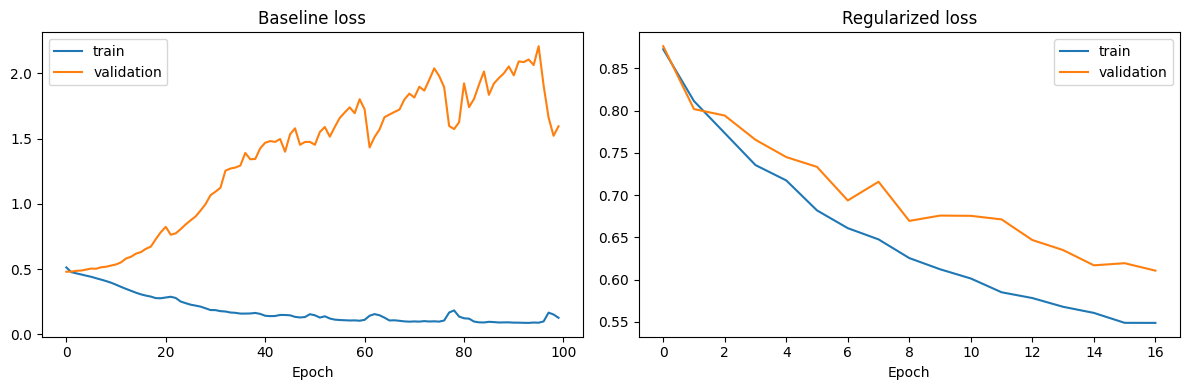

In [24]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(hist_base.history["loss"], label="train")
plt.plot(hist_base.history["val_loss"], label="validation")
plt.title("Baseline loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_reg.history["loss"], label="train")
plt.plot(hist_reg.history["val_loss"], label="validation")
plt.title("Regularized loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

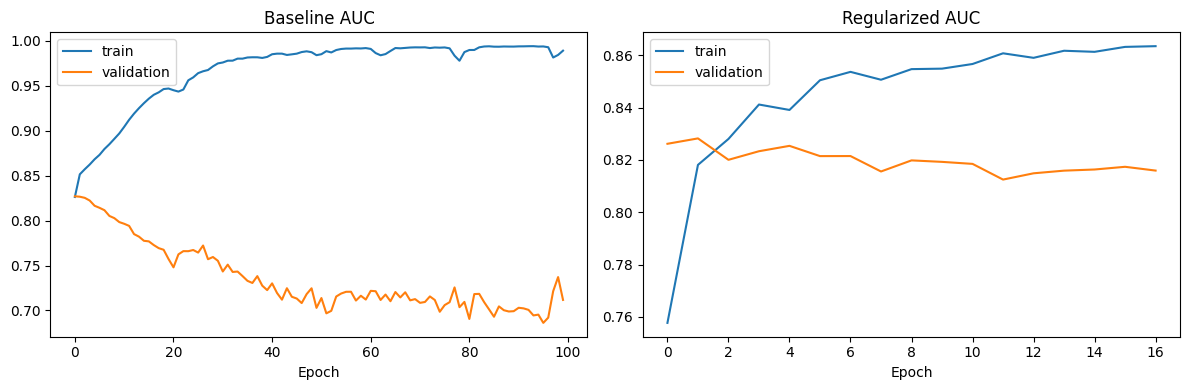

In [25]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(hist_base.history["auc"], label="train")
plt.plot(hist_base.history["val_auc"], label="validation")
plt.title("Baseline AUC")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_reg.history["auc"], label="train")
plt.plot(hist_reg.history["val_auc"], label="validation")
plt.title("Regularized AUC")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

## 8. Hyperparameter Tuning

### 8.1 Keras Tuner (Random Search)

In [26]:
def build_model(hp):
    n_layers = hp.Int("n_layers", 1, 3)
    dropout = hp.Float("dropout", 0.0, 0.5, step=0.1)
    l2_value = hp.Choice("l2", [0.0, 0.0001, 0.001, 0.01])
    lr = hp.Choice("lr", [0.01, 0.001, 0.0005, 0.0001])
    use_bn = hp.Boolean("batchnorm")

    model = keras.Sequential()
    model.add(keras.Input(shape=(INPUT_DIM,)))

    for i in range(n_layers):
        units = hp.Choice("units_" + str(i), [32, 64, 128, 256])
        if l2_value > 0:
            model.add(layers.Dense(units, kernel_regularizer=regularizers.l2(l2_value)))
        else:
            model.add(layers.Dense(units))
        if use_bn:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))

    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=METRICS)
    return model


tuner = kt.RandomSearch(
    build_model,
    objective=kt.Objective("val_auc", direction="max"),
    max_trials=20,
    executions_per_trial=1,
    directory="tuner_churn",
    project_name="churn_ann",
    overwrite=True,
    seed=SEED
)
tuner.search_space_summary()

Search space summary
Default search space size: 6
n_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
dropout (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
l2 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.0001, 0.001, 0.01], 'ordered': True}
lr (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0005, 0.0001], 'ordered': True}
batchnorm (Boolean)
{'default': False, 'conditions': []}
units_0 (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 128, 256], 'ordered': True}


In [27]:
tuner.search(X_train, y_train,
             validation_data=(X_val, y_val),
             epochs=100,
             batch_size=32,
             class_weight=CLASS_WEIGHT,
             callbacks=[callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                                patience=10, restore_best_weights=True)],
             verbose=1)

tuner.results_summary(num_trials=5)
best_hp = tuner.get_best_hyperparameters(1)[0]
print(best_hp.values)

Trial 20 Complete [00h 00m 28s]
val_auc: 0.8019468188285828

Best val_auc So Far: 0.8347032070159912
Total elapsed time: 00h 07m 34s
Results summary
Results in tuner_churn/churn_ann
Showing 5 best trials
Objective(name="val_auc", direction="max")

Trial 12 summary
Hyperparameters:
n_layers: 2
dropout: 0.2
l2: 0.001
lr: 0.0005
batchnorm: False
units_0: 32
units_1: 32
units_2: 256
Score: 0.8347032070159912

Trial 14 summary
Hyperparameters:
n_layers: 1
dropout: 0.4
l2: 0.001
lr: 0.0001
batchnorm: True
units_0: 32
units_1: 128
units_2: 64
Score: 0.8339359164237976

Trial 16 summary
Hyperparameters:
n_layers: 1
dropout: 0.0
l2: 0.0
lr: 0.0005
batchnorm: False
units_0: 256
units_1: 256
units_2: 64
Score: 0.8334379196166992

Trial 10 summary
Hyperparameters:
n_layers: 1
dropout: 0.30000000000000004
l2: 0.01
lr: 0.0005
batchnorm: False
units_0: 128
units_1: 32
units_2: 256
Score: 0.8334035277366638

Trial 07 summary
Hyperparameters:
n_layers: 3
dropout: 0.2
l2: 0.01
lr: 0.001
batchnorm: False

### 8.2 Manual Tuning (batch size)

In [28]:
batch_results = []

for bs in [16, 32, 64, 128]:
    keras.utils.set_random_seed(SEED)
    model = tuner.hypermodel.build(best_hp)
    start = time.time()
    h = model.fit(X_train, y_train,
                  validation_data=(X_val, y_val),
                  epochs=200,
                  batch_size=bs,
                  class_weight=CLASS_WEIGHT,
                  callbacks=[callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                                     patience=15, restore_best_weights=True)],
                  verbose=0)
    batch_results.append({"batch_size": bs,
                          "best_val_auc": max(h.history["val_auc"]),
                          "epochs": len(h.history["loss"]),
                          "time_s": round(time.time() - start, 1)})

batch_df = pd.DataFrame(batch_results)
print(batch_df)

BEST_BATCH = int(batch_df.loc[batch_df["best_val_auc"].idxmax(), "batch_size"])
print("Best batch size:", BEST_BATCH)

   batch_size  best_val_auc  epochs  time_s
0          16      0.829846      21    32.2
1          32      0.828168      30    25.3
2          64      0.828288      36    21.0
3         128      0.827332      39    17.7
Best batch size: 16


### 8.3 Final Model

In [29]:
keras.utils.set_random_seed(SEED)
final_model = tuner.hypermodel.build(best_hp)
final_model.summary()

hist_final = final_model.fit(X_train, y_train,
                             validation_data=(X_val, y_val),
                             epochs=200,
                             batch_size=BEST_BATCH,
                             class_weight=CLASS_WEIGHT,
                             callbacks=[callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                                                patience=20,
                                                                restore_best_weights=True),
                                        callbacks.ReduceLROnPlateau(monitor="val_loss",
                                                                    factor=0.5, patience=7,
                                                                    min_lr=0.00001)],
                             verbose=0)
print("Epochs trained:", len(hist_final.history["loss"]))

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 32)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,241 (8.75 KB)

 Trainable params: 2,241 (8.75 KB)

 Non-trainable params: 0 (0.00 B)

Epochs trained: 26


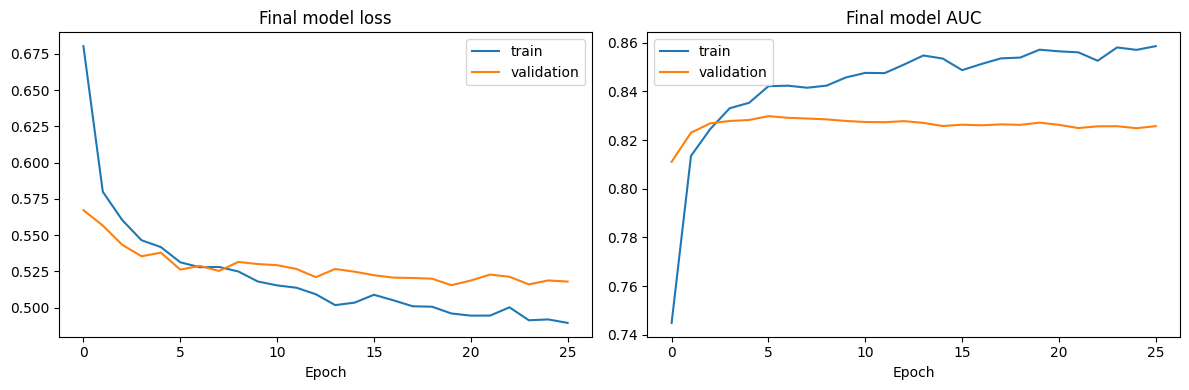

In [30]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(hist_final.history["loss"], label="train")
plt.plot(hist_final.history["val_loss"], label="validation")
plt.title("Final model loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_final.history["auc"], label="train")
plt.plot(hist_final.history["val_auc"], label="validation")
plt.title("Final model AUC")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

## 9. Evaluation

### 9.1 Decision Threshold

In [31]:
val_prob = final_model.predict(X_val, verbose=0).ravel()

prec_list, rec_list, thr_list = precision_recall_curve(y_val, val_prob)
f1_list = 2 * prec_list[:-1] * rec_list[:-1] / (prec_list[:-1] + rec_list[:-1] + 0.000000001)

BEST_THRESHOLD = float(thr_list[np.argmax(f1_list)])
print("Best threshold:", round(BEST_THRESHOLD, 3))
print("Validation F1 at that threshold:", round(max(f1_list), 4))

Best threshold: 0.523
Validation F1 at that threshold: 0.6154


### 9.2 Metrics on the Test Set

In [32]:
def get_scores(name, y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    scores = {}
    scores["Model"] = name
    scores["Threshold"] = round(threshold, 3)
    scores["Accuracy"] = accuracy_score(y_true, y_pred)
    scores["Precision"] = precision_score(y_true, y_pred)
    scores["Recall"] = recall_score(y_true, y_pred)
    scores["F1"] = f1_score(y_true, y_pred)
    scores["ROC-AUC"] = roc_auc_score(y_true, y_prob)
    scores["PR-AUC"] = average_precision_score(y_true, y_prob)
    return scores


prob_base = baseline.predict(X_test, verbose=0).ravel()
prob_reg = regularized.predict(X_test, verbose=0).ravel()
prob_final = final_model.predict(X_test, verbose=0).ravel()

rows = []
rows.append(get_scores("ANN baseline", y_test, prob_base, 0.5))
rows.append(get_scores("ANN regularized", y_test, prob_reg, 0.5))
rows.append(get_scores("ANN tuned", y_test, prob_final, 0.5))
rows.append(get_scores("ANN tuned (best threshold)", y_test, prob_final, BEST_THRESHOLD))

results_df = pd.DataFrame(rows).set_index("Model").round(4)
results_df

,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,,
ANN baseline,0.500,0.7406,0.5115,0.5374,0.5241,0.7396,0.4639
ANN regularized,0.500,0.7214,0.4860,0.8369,0.6149,0.8322,0.6037
ANN tuned,0.500,0.7413,0.5088,0.7701,0.6128,0.8313,0.6062
ANN tuned (best threshold),0.523,0.7484,0.5185,0.7487,0.6127,0.8313,0.6062


In [33]:
y_pred_final = (prob_final >= BEST_THRESHOLD).astype(int)
print(classification_report(y_test, y_pred_final, target_names=["Stay", "Churn"]))

              precision    recall  f1-score   support

        Stay       0.89      0.75      0.81      1033
       Churn       0.52      0.75      0.61       374

    accuracy                           0.75      1407
   macro avg       0.71      0.75      0.71      1407
weighted avg       0.79      0.75      0.76      1407



<Figure size 600x500 with 0 Axes>

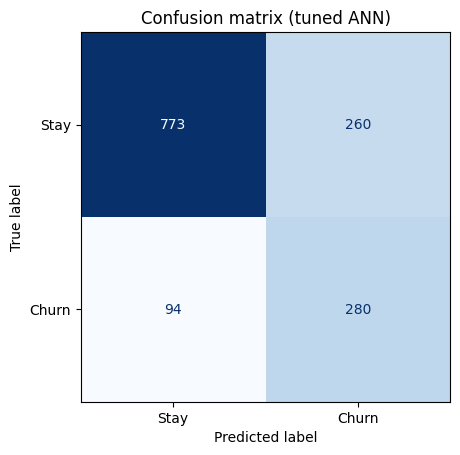

In [34]:
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_final)
ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix (tuned ANN)")
plt.show()

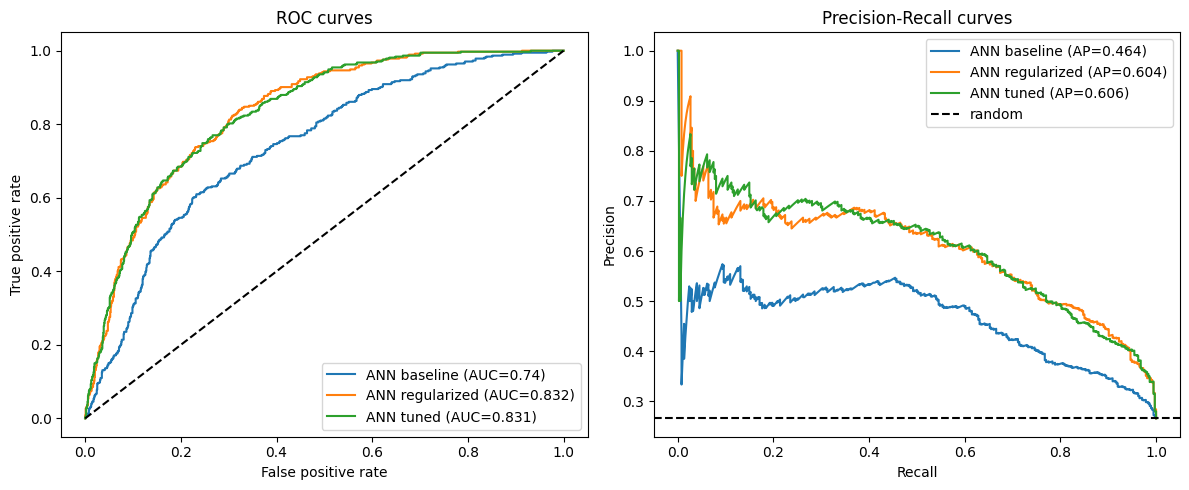

In [35]:
all_probs = {"ANN baseline": prob_base,
             "ANN regularized": prob_reg,
             "ANN tuned": prob_final}

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for name in all_probs:
    fpr, tpr, _ = roc_curve(y_test, all_probs[name])
    plt.plot(fpr, tpr, label=name + " (AUC=" + str(round(roc_auc_score(y_test, all_probs[name]), 3)) + ")")
plt.plot([0, 1], [0, 1], "k--")
plt.title("ROC curves")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()

plt.subplot(1, 2, 2)
for name in all_probs:
    pr, rc, _ = precision_recall_curve(y_test, all_probs[name])
    plt.plot(rc, pr, label=name + " (AP=" + str(round(average_precision_score(y_test, all_probs[name]), 3)) + ")")
plt.axhline(y_test.mean(), color="k", linestyle="--", label="random")
plt.title("Precision-Recall curves")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()

plt.tight_layout()
plt.show()

## 10. Model Saving and Loading

In [36]:
os.makedirs("artifacts", exist_ok=True)

final_model.save("artifacts/churn_model.keras")
joblib.dump(scaler, "artifacts/scaler.joblib")

config = {"threshold": BEST_THRESHOLD,
          "feature_names": FEATURE_NAMES,
          "binary_cols": BINARY_COLS,
          "multi_cols": MULTI_COLS,
          "yes_services": YES_SERVICES,
          "tenure_bins": TENURE_BINS,
          "tenure_labels": TENURE_LABELS}

with open("artifacts/config.json", "w") as f:
    json.dump(config, f, indent=2)

print(os.listdir("artifacts"))

['scaler.joblib', 'config.json', 'churn_model.keras']


In [37]:
loaded_model = keras.models.load_model("artifacts/churn_model.keras")
loaded_scaler = joblib.load("artifacts/scaler.joblib")

with open("artifacts/config.json") as f:
    loaded_config = json.load(f)

prob_loaded = loaded_model.predict(X_test, verbose=0).ravel()
print("Same predictions:", np.allclose(prob_final, prob_loaded, atol=0.000001))

Same predictions: True


## 11. Inference Pipeline

In [38]:
def prepare_customer(customer, config):
    row = pd.DataFrame([customer])

    row["TotalCharges"] = pd.to_numeric(row["TotalCharges"], errors="coerce").fillna(0)
    row["AvgChargePerMonth"] = row["TotalCharges"] / row["tenure"].replace(0, 1)

    row["TotalServices"] = 0
    for col in config["yes_services"]:
        row["TotalServices"] = row["TotalServices"] + (row[col] == "Yes").astype(int)
    row["TotalServices"] = row["TotalServices"] + (row["InternetService"] != "No").astype(int)

    row["TenureGroup"] = pd.cut(row["tenure"],
                                bins=config["tenure_bins"],
                                labels=config["tenure_labels"])

    for col in config["binary_cols"]:
        row[col] = row[col].map({"No": 0, "Yes": 1})

    row["gender"] = row["gender"].map({"Female": 0, "Male": 1})

    row = pd.get_dummies(row, columns=config["multi_cols"])
    row = row.reindex(columns=config["feature_names"], fill_value=0)
    row = row.astype(float)
    return row


def predict_churn(customer, model=None, scaler_obj=None, config=None):
    if model is None:
        model = loaded_model
    if scaler_obj is None:
        scaler_obj = loaded_scaler
    if config is None:
        config = loaded_config

    row = prepare_customer(customer, config)
    row_scaled = scaler_obj.transform(row).astype("float32")
    prob = float(model.predict(row_scaled, verbose=0)[0][0])

    result = {}
    result["churn_probability"] = round(prob, 4)
    if prob >= config["threshold"]:
        result["prediction"] = "Churn"
    else:
        result["prediction"] = "Stay"
    return result

In [39]:
new_customer = {"gender": "Female",
                "SeniorCitizen": 0,
                "Partner": "No",
                "Dependents": "No",
                "tenure": 2,
                "PhoneService": "Yes",
                "MultipleLines": "No",
                "InternetService": "Fiber optic",
                "OnlineSecurity": "No",
                "OnlineBackup": "No",
                "DeviceProtection": "No",
                "TechSupport": "No",
                "StreamingTV": "Yes",
                "StreamingMovies": "Yes",
                "Contract": "Month-to-month",
                "PaperlessBilling": "Yes",
                "PaymentMethod": "Electronic check",
                "MonthlyCharges": 95.5,
                "TotalCharges": 191.0}

predict_churn(new_customer)

{'churn_probability': 0.8783, 'prediction': 'Churn'}

In [40]:
loyal_customer = {"gender": "Male",
                  "SeniorCitizen": 0,
                  "Partner": "Yes",
                  "Dependents": "Yes",
                  "tenure": 65,
                  "PhoneService": "Yes",
                  "MultipleLines": "Yes",
                  "InternetService": "DSL",
                  "OnlineSecurity": "Yes",
                  "OnlineBackup": "Yes",
                  "DeviceProtection": "Yes",
                  "TechSupport": "Yes",
                  "StreamingTV": "No",
                  "StreamingMovies": "No",
                  "Contract": "Two year",
                  "PaperlessBilling": "No",
                  "PaymentMethod": "Bank transfer (automatic)",
                  "MonthlyCharges": 65.0,
                  "TotalCharges": 4200.0}

predict_churn(loyal_customer)

{'churn_probability': 0.0392, 'prediction': 'Stay'}

## 12. Deployment (Streamlit app)

The next cell writes `app.py`. To run it:

```
pip install streamlit
streamlit run app.py
```

`app.py` must be in the same folder as the `artifacts` folder.

In [ ]:
%%writefile app.py
import json
import joblib
import pandas as pd
import streamlit as st
from tensorflow import keras


@st.cache_resource
def load_everything():
    model = keras.models.load_model("artifacts/churn_model.keras")
    scaler = joblib.load("artifacts/scaler.joblib")
    with open("artifacts/config.json") as f:
        config = json.load(f)
    return model, scaler, config


def prepare_customer(customer, config):
    row = pd.DataFrame([customer])

    row["TotalCharges"] = pd.to_numeric(row["TotalCharges"], errors="coerce").fillna(0)
    row["AvgChargePerMonth"] = row["TotalCharges"] / row["tenure"].replace(0, 1)

    row["TotalServices"] = 0
    for col in config["yes_services"]:
        row["TotalServices"] = row["TotalServices"] + (row[col] == "Yes").astype(int)
    row["TotalServices"] = row["TotalServices"] + (row["InternetService"] != "No").astype(int)

    row["TenureGroup"] = pd.cut(row["tenure"],
                                bins=config["tenure_bins"],
                                labels=config["tenure_labels"])

    for col in config["binary_cols"]:
        row[col] = row[col].map({"No": 0, "Yes": 1})

    row["gender"] = row["gender"].map({"Female": 0, "Male": 1})

    row = pd.get_dummies(row, columns=config["multi_cols"])
    row = row.reindex(columns=config["feature_names"], fill_value=0)
    row = row.astype(float)
    return row


model, scaler, config = load_everything()

st.set_page_config(page_title="Customer Churn Prediction")
st.title("Customer Churn Prediction")
st.write("Enter the customer details to get the probability of churn.")

YES_NO = ["No", "Yes"]
SERVICE = ["No", "Yes", "No internet service"]

col1, col2 = st.columns(2)

with col1:
    st.subheader("Customer")
    gender = st.selectbox("Gender", ["Female", "Male"])
    senior = st.selectbox("Senior citizen", YES_NO)
    partner = st.selectbox("Partner", YES_NO)
    dependents = st.selectbox("Dependents", YES_NO)
    tenure = st.slider("Tenure (months)", 0, 72, 12)

    st.subheader("Billing")
    contract = st.selectbox("Contract", ["Month-to-month", "One year", "Two year"])
    paperless = st.selectbox("Paperless billing", YES_NO)
    payment = st.selectbox("Payment method", ["Electronic check", "Mailed check",
                                              "Bank transfer (automatic)",
                                              "Credit card (automatic)"])
    monthly = st.number_input("Monthly charges", 0.0, 200.0, 70.0, step=0.5)
    total = st.number_input("Total charges", 0.0, 10000.0, float(round(monthly * tenure, 2)), step=10.0)

with col2:
    st.subheader("Services")
    phone = st.selectbox("Phone service", YES_NO, index=1)
    multiple = st.selectbox("Multiple lines", ["No", "Yes", "No phone service"])
    internet = st.selectbox("Internet service", ["DSL", "Fiber optic", "No"])
    security = st.selectbox("Online security", SERVICE)
    backup = st.selectbox("Online backup", SERVICE)
    protection = st.selectbox("Device protection", SERVICE)
    support = st.selectbox("Tech support", SERVICE)
    tv = st.selectbox("Streaming TV", SERVICE)
    movies = st.selectbox("Streaming movies", SERVICE)

if st.button("Predict"):
    customer = {"gender": gender,
                "SeniorCitizen": 1 if senior == "Yes" else 0,
                "Partner": partner,
                "Dependents": dependents,
                "tenure": tenure,
                "PhoneService": phone,
                "MultipleLines": multiple,
                "InternetService": internet,
                "OnlineSecurity": security,
                "OnlineBackup": backup,
                "DeviceProtection": protection,
                "TechSupport": support,
                "StreamingTV": tv,
                "StreamingMovies": movies,
                "Contract": contract,
                "PaperlessBilling": paperless,
                "PaymentMethod": payment,
                "MonthlyCharges": monthly,
                "TotalCharges": total}

    row = prepare_customer(customer, config)
    row_scaled = scaler.transform(row).astype("float32")
    prob = float(model.predict(row_scaled, verbose=0)[0][0])

    st.metric("Churn probability", str(round(prob * 100, 1)) + "%")
    st.progress(min(prob, 1.0))

    if prob >= config["threshold"]:
        st.error("High risk: this customer is likely to churn.")
    else:
        st.success("Low risk: this customer is likely to stay.")

    st.caption("Decision threshold: " + str(round(config["threshold"], 3)))

## 13. Conclusion

The pipeline covers cleaning, feature engineering, encoding, scaling, an ANN, regularization, Keras Tuner and manual tuning, threshold selection, evaluation, saving and loading, and an inference function with a Streamlit app.

Preprocessing choices used here:
- rows with blank `TotalCharges` were dropped instead of filled
- three new features were added: `AvgChargePerMonth`, `TotalServices`, `TenureGroup`
- binary columns were mapped to 0 and 1, and the rest encoded with `get_dummies(drop_first=True)`
- scaling was done with `MinMaxScaler` fitted on the training set only
- the split was 64% train, 16% validation, 20% test